In [59]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from skimage import io, exposure
from skimage.color import rgb2gray
from skimage.filters import threshold_otsu, gaussian
from skimage.measure import label, regionprops

In [60]:
# Cartella di output per il salvataggio dei risultati grafici
OUTPUT_DIR = Path(fr"C:/Users/lucaasinari/Desktop/Tesi ESPCI/script_rheoflu/results/phase_diagram/ATP_PLL_coac")
if not OUTPUT_DIR.is_absolute() or not OUTPUT_DIR.drive or not Path(OUTPUT_DIR.drive + "/").exists():
    OUTPUT_DIR = Path(str(OUTPUT_DIR).replace("C:", "").replace("c:", ""))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"I grafici verranno salvati in: {OUTPUT_DIR}")

folder_path = Path("/Users/lucaasinari/Desktop/Tesi ESPCI/esperimenti/data/nanodrop/NanodropOne_AZY2123940")
filenames = [
    "UV-Vis 10_19_2026 2_55_02 PM.csv",
    "UV-Vis 10_28_2026 6_44_08 PM.csv",
    "UV-Vis 10_29_2026 6_15_44 PM.csv"
]
pixel_size_um = 62/280

# Funzione di lettura flessibile (gestisce sia file salvati da Excel sia file grezzi NanoDrop)
def load_nanodrop(path):
    try:
        df = pd.read_csv(path, sep=None, engine="python").dropna(how="all", axis=1)
        if df.shape[1] > 1:
            return df
    except Exception:
        pass
    return pd.read_csv(path, sep="\t", encoding="utf-16").dropna(how="all", axis=1)

dfs = []
for fname in filenames:
    file_csv = folder_path / fname
    print(f"Caricamento file: {file_csv.name}")
    dfs.append(load_nanodrop(file_csv))


df = pd.concat(dfs, ignore_index=True)
print(f"\nTotale campioni caricati: {len(df)}\n")

# Mostra la tabella a video
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
print(df.to_string(index=False))

I grafici verranno salvati in: /Users/lucaasinari/Desktop/Tesi ESPCI/script_rheoflu/results/phase_diagram/ATP_PLL_coac
Caricamento file: UV-Vis 10_19_2026 2_55_02 PM.csv
Caricamento file: UV-Vis 10_28_2026 6_44_08 PM.csv
Caricamento file: UV-Vis 10_29_2026 6_15_44 PM.csv

Totale campioni caricati: 51

                 Date    Sample Name Automated Pathlength Analytical Wavelength  245 nm  250 nm  255 nm  260 nm  265 nm  270 nm  275 nm  244 nm  246 nm  251 nm  256 nm  261 nm  266 nm  271 nm  276 nm  243 nm  247 nm  252 nm  257 nm  262 nm  267 nm  272 nm  277 nm  242 nm  248 nm  253 nm  258 nm  263 nm  268 nm  273 nm  278 nm  241 nm  249 nm  254 nm  259 nm  264 nm  269 nm  274 nm  279 nm  240 nm Baseline Correction (nm)  230 nm  280 nm
10/19/2026 2:54:58 PM       Sample 1                  OFF                   OFF    1.82    2.45    2.98    3.16    2.91    2.14    1.23    1.70    1.97    2.58    3.05    3.13    2.79    1.94    1.09    1.60    2.10    2.71    3.11    3.10    2.66    1.76 

In [61]:
# 1. Usa df già caricato nella Cella 1 (o lo ricarica se mancante)
if "df" not in globals() or df is None:
    folder_path = Path("/Users/lucaasinari/Desktop/Tesi ESPCI/esperimenti/data/nanodrop/NanodropOne_AZY2123940")
    if not folder_path.exists():
        folder_path = Path("/Users/lucaasinari/Desktop/NanodropOne_AZY2123940")
    filenames = [
        "UV-Vis 10_19_2026 2_55_02 PM.csv",
        "UV-Vis 10_28_2026 6_44_08 PM.csv",
        "UV-Vis 10_29_2026 6_15_44 PM.csv"
    ]
    df = pd.concat([load_nanodrop(folder_path / fn) for fn in filenames], ignore_index=True)

# Identifica le colonne corrette
col_259 = [c for c in df.columns if "259" in str(c)][0]
sample_col = "Sample Name"

# -------------------------------------------------------------
# FUNZIONE: Filtro Outlier Robusto
# -------------------------------------------------------------
def filter_outliers_robust(values, threshold=0.20, min_samples=3):
    vals = np.array(values, dtype=float)
    vals = vals[~np.isnan(vals)]
    if len(vals) < min_samples:
        return vals.tolist(), []
    median_val = np.median(vals)
    if abs(median_val) < 1e-6:
        relative_diff = np.abs(vals - median_val)
    else:
        relative_diff = np.abs(vals - median_val) / abs(median_val)
    kept = vals[relative_diff <= threshold].tolist()
    excluded = vals[relative_diff > threshold].tolist()
    if not kept:
        return vals.tolist(), []
    return kept, excluded

# -------------------------------------------------------------
# 2. Raggruppamento e Calcolo Medie per i campioni di sale
# -------------------------------------------------------------
# Considera solo i campioni con nome che inizia con una cifra
df_valid = df[df[sample_col].astype(str).str.match(r"^\d")].copy()
df_valid["molarity"] = df_valid[sample_col].astype(str).str.extract(r"^(\d+(?:\.\d+)?)")[0].astype(float)
df_valid[col_259] = pd.to_numeric(df_valid[col_259], errors="coerce")

salt_list = []
absorbance_list = []
print(f"{'Molarità':<10} | {'Replicati grezzi':<35} | {'Outlier rimossi':<20} | {'Media finale':<12}")
print("-" * 85)
for molarity, group in df_valid.groupby("molarity", sort=True):
    raw_vals = group[col_259].dropna().tolist()
    kept_vals, excluded_vals = filter_outliers_robust(raw_vals, threshold=0.20)
    mean_val = np.mean(kept_vals)
    salt_list.append(molarity)
    absorbance_list.append(mean_val)
    raw_str = str([round(x, 2) for x in raw_vals])
    excl_str = str([round(x, 2) for x in excluded_vals]) if excluded_vals else "Nessuno"
    print(f"{molarity:<10} | {raw_str:<35} | {excl_str:<20} | {mean_val:<12.2f}")

# 3. Array NumPy finali
SALT = np.array(salt_list)
ABSORBANCE = np.array(absorbance_list)

# -------------------------------------------------------------
# 4. Calcolo media per campioni 'ATP 2.5mM'
# -------------------------------------------------------------
df_atp = df[df[sample_col].astype(str).str.match(r"^atp\s*10\s*mm", case=False)].copy()
df_atp[col_259] = pd.to_numeric(df_atp[col_259], errors="coerce")
raw_atp = df_atp[col_259].dropna().tolist()
kept_atp, excluded_atp = filter_outliers_robust(raw_atp, threshold=0.20)
ATP_ABSORBANCE = np.mean(kept_atp) if kept_atp else np.nan

print("-" * 85)
print(f"ATP 2,5mM   | {str([round(x, 2) for x in raw_atp]):<35} | {str([round(x, 2) for x in excluded_atp]) if excluded_atp else 'Nessuno':<20} | {ATP_ABSORBANCE:<12.2f}")

print("\n--- RISULTATI ---")
print("SALT:                ", SALT)
print("ABSORBANCE:          ", np.round(ABSORBANCE, 2))
print("ATP 2,5mM ABSORBANCE: ", round(ATP_ABSORBANCE, 2) if not np.isnan(ATP_ABSORBANCE) else "N/A")


Molarità   | Replicati grezzi                    | Outlier rimossi      | Media finale
-------------------------------------------------------------------------------------
0.0        | [0.95, 0.96]                        | Nessuno              | 0.95        
50.0       | [2.05, 1.06, 2.03, 2.12]            | [1.06]               | 2.07        
100.0      | [6.1, 5.96, 0.07]                   | [0.07]               | 6.03        
150.0      | [8.04, 8.38, 0.05]                  | [0.05]               | 8.21        
200.0      | [15.07, 15.22, 15.88, 16.06]        | Nessuno              | 15.56       
250.0      | [25.32, 25.49, 23.18, 25.87, 20.81, 50.34, 23.68] | [50.34]              | 24.06       
300.0      | [25.76, 26.64, 26.65]               | Nessuno              | 26.35       
350.0      | [36.13, 36.75, 37.42]               | Nessuno              | 36.77       
400.0      | [37.28, 37.61, 36.71, 3.76, 35.98, 35.98, 34.36] | [3.76]               | 36.32       
450.0      | [36.

/var/folders/jv/zgsyfff5147d12l37s8448th0000gn/T/ipykernel_8127/648481481.py:28: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x_ref[mask_sup], SALT[mask_sup], marker="x", color="#195e8f", s=80, edgecolors="black", linewidth=1.2, alpha=0.3, zorder=3)


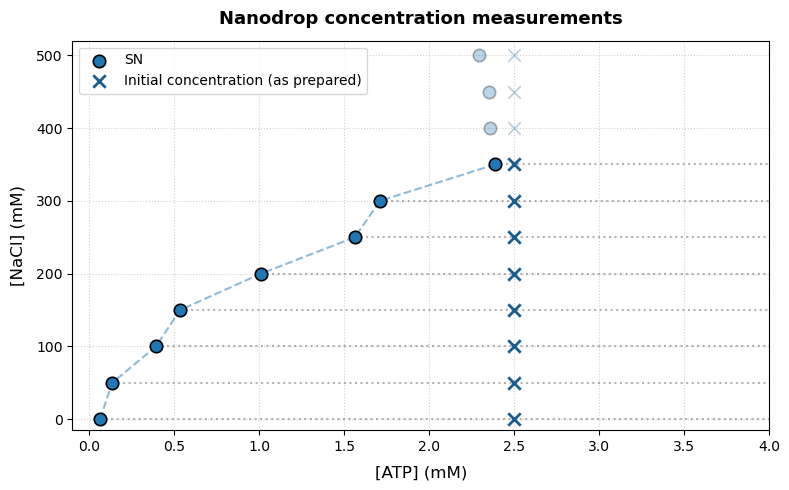

In [62]:
critical_point = 350

# Se hai un fattore di conversione da assorbanza a concentrazione (Legge di Lambert-Beer: A = ε * b * c),
# puoi impostarlo qui sotto. Di default usiamo direttamente i valori di ABSORBANCE (a 259 nm).
extinction_factor = 15.4 #mM^{-1} cm^{-1} (epsilon * cammino_ottico=1)
SN_concentration = np.array(ABSORBANCE) / extinction_factor
SALT = np.array(SALT)

mask_sub = SALT <= critical_point
mask_sup = SALT > critical_point

plt.figure(figsize=(8, 5), dpi=100)

# Scatter plot: Concentrazione sulle ascisse (X), Concentrazione di Sale sulle ordinate (Y)
# Punti <= critical_point opachi, punti > critical_point in trasparenza
plt.scatter(SN_concentration[mask_sub], SALT[mask_sub], color="#1f77b4", s=80, edgecolors="black", linewidth=1.2, zorder=3, label="SN")
if np.any(mask_sup):
    plt.scatter(SN_concentration[mask_sup], SALT[mask_sup], color="#1f77b4", s=80, edgecolors="black", linewidth=1.2, alpha=0.3, zorder=3)

# Linea tratteggiata per visualizzare il trend del diagramma di fase (SOLO per punti <= critical_point)
sort_idx = np.argsort(SALT[mask_sub])
plt.plot(SN_concentration[mask_sub][sort_idx], SALT[mask_sub][sort_idx], linestyle="--", color="#1f77b4", alpha=0.5, zorder=2)

# Punti a x = 10 allineati in orizzontale (stesso valore di SALT)
x_ref = np.full_like(SALT, 2.5)
plt.scatter(x_ref[mask_sub], SALT[mask_sub], marker="x", color="#195e8f", s=80, linewidth=2.0, zorder=3, label="Initial concentration (as prepared)")
if np.any(mask_sup):
    plt.scatter(x_ref[mask_sup], SALT[mask_sup], marker="x", color="#195e8f", s=80, edgecolors="black", linewidth=1.2, alpha=0.3, zorder=3)

# Linee orizzontali di collegamento tra i punti misurati e x = 10 (SOLO per punti <= critical_point)
for c, s in zip(SN_concentration[mask_sub], SALT[mask_sub]):
    plt.plot([c, 10], [s, s], linestyle=":", color="gray", alpha=0.6, zorder=2)

# Retta verticale soluzione di ATP 2.5mM misurato al nanodrop
#if "ATP_ABSORBANCE" in globals() and not np.isnan(ATP_ABSORBANCE):
#    atp_10mM_conc = ATP_ABSORBANCE / extinction_factor
#    plt.axvline(x=atp_10mM_conc, color="#ff7f0e", linestyle="--", linewidth=1.5, alpha=0.8, zorder=2, label=f"ATP 2.5mM (as prepared)")

# Dettagli del grafico
plt.xlabel("[ATP] (mM)", fontsize=12, labelpad=8)
plt.ylabel("[NaCl] (mM)", fontsize=12, labelpad=8)
plt.title("Nanodrop concentration measurements", fontsize=13, fontweight="bold", pad=12)
plt.grid(True, linestyle=":", alpha=0.6, zorder=1)
plt.legend(frameon=True)
plt.xlim(-.1, 4)
plt.ylim(-15, 520)
plt.tight_layout()

# Salvataggio grafico
plt.savefig(OUTPUT_DIR / "nanodrop_measurements.png", dpi=300)
plt.show()

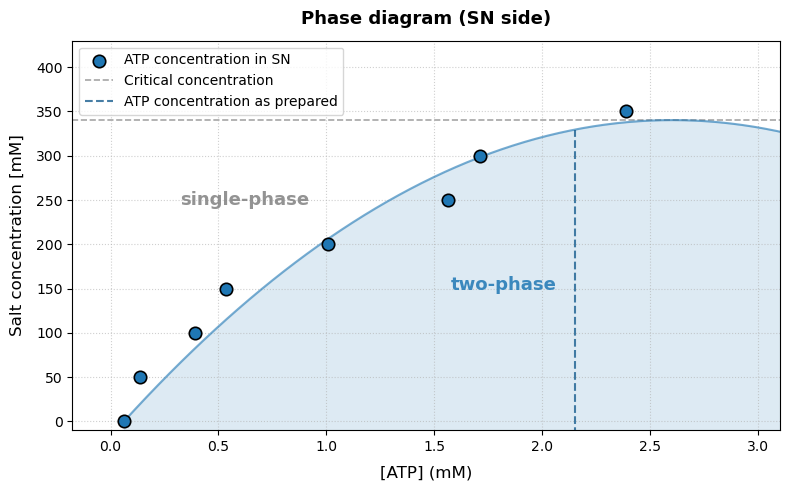

In [63]:
plt.figure(figsize=(8, 5), dpi=100)

# Scatter plot: punti <= critical_point opachi, punti > critical_point in trasparenza
plt.scatter(SN_concentration[mask_sub], SALT[mask_sub], color="#1f77b4", s=80, edgecolors="black", linewidth=1.2, zorder=3, label="ATP concentration in SN")
if np.any(mask_sup):
    plt.scatter(SN_concentration[mask_sup], SALT[mask_sup], color="#1f77b4", s=0, edgecolors="black", linewidth=1.2, alpha=0.3, zorder=3)

# --- INIZIO FIT FORZATO SUL PRIMO PUNTO (SOLO PUNTI <= CRITICAL POINT) ---
sort_idx = np.argsort(SN_concentration[mask_sub])
x_sorted = SN_concentration[mask_sub][sort_idx]
y_sorted = SALT[mask_sub][sort_idx]

x_start = x_sorted[0]
y_start = y_sorted[0]

def poly_custom(x, a, b):
    return y_start + a * (x - x_start) + b * (x - x_start)**2

popt, _ = curve_fit(poly_custom, x_sorted, y_sorted)

x_max = np.max(x_sorted)
x_extended = np.linspace(x_start, x_max * 1.5, 200) 
y_smooth = poly_custom(x_extended, *popt)

valid_curve = y_smooth <= critical_point
plt.plot(x_extended[valid_curve], y_smooth[valid_curve], linestyle="-", color="#1f77b4", alpha=0.6, zorder=2)#, label="Trend curve")

# COLORIAMO IL SOTTO DELLA CURVA IN TRASPARENZA
plt.fill_between(
    x_extended[valid_curve], 
    y_smooth[valid_curve], 
    y2=-15,                
    color="#1f77b4",       
    alpha=0.15,            
    zorder=1               
)
# --- FINE FIT ---

# 1. Linea orizzontale al critical point
plt.axhline(y=critical_point-10, color="gray", linestyle="--", linewidth=1.2, alpha=0.7, zorder=1, label=f"Critical concentration")

# 2. Retta verticale ATP che si ferma sulla curva
atp_x = ATP_ABSORBANCE / extinction_factor
    # Calcoliamo la Y esatta in cui l'ATP incontra la curva trend
atp_y_intersect = poly_custom(atp_x, *popt)
    
    # Se il punto di intersezione supera il critical_point, la blocchiamo lì
if atp_y_intersect > critical_point:
    atp_y_intersect = critical_point
        
plt.vlines(x=atp_x, ymin=-15, ymax=atp_y_intersect, color="#195e8f", linestyle="--", linewidth=1.5, alpha=0.8, zorder=2, label="ATP concentration as prepared")

# 3. Scritte nel grafico (two-phase e one-phase)
# Calcoliamo una X media basata sulla curva per centrare le scritte
x_text_center = np.mean(x_extended[valid_curve])

# "two-phase" a metà altezza della curva
y_two_phase = poly_custom(x_text_center, *popt) / 2
plt.text(x_text_center, y_two_phase, "two-phase", fontsize=13, fontweight="bold", color="#1f77b4", alpha=0.85, ha="center", va="center")

# "one-phase" nello spazio bianco sopra la curva
y_one_phase = critical_point - 100
plt.text(x_text_center-1.2, y_one_phase, "single-phase", fontsize=13, fontweight="bold", color="gray", alpha=0.85, ha="center", va="center")


# Dettagli del grafico
plt.xlabel("[ATP] (mM)", fontsize=12, labelpad=8)
plt.ylabel("Salt concentration [mM]", fontsize=12, labelpad=8)
plt.title("Phase diagram (SN side)", fontsize=13, fontweight="bold", pad=12)
plt.grid(True, linestyle=":", alpha=0.6, zorder=1)

# Sposta la legenda fuori se copre le scritte, oppure mantienila integrata
plt.legend(frameon=True, loc="upper left")

# Impostiamo i limiti
x_all_max = np.max(SN_concentration)
if "ATP_ABSORBANCE" in globals() and not np.isnan(ATP_ABSORBANCE):
    x_all_max = max(x_all_max, atp_x)
plt.xlim(x_start - (x_all_max * 0.1), x_all_max * 1.3) 
plt.ylim(-10, 430) 
plt.tight_layout()

# Salvataggio grafico
plt.savefig(OUTPUT_DIR / "phase_diagram_SN_side.png", dpi=300)
plt.show()

Totale coacervati rilevati: 1325


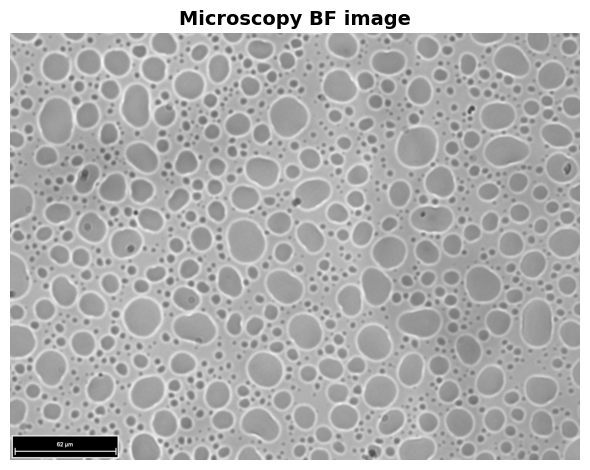

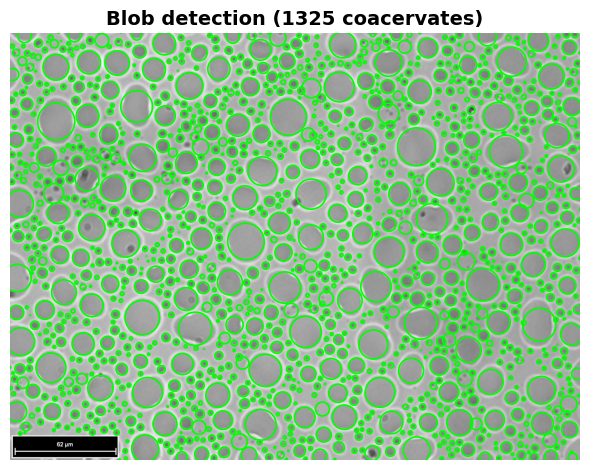

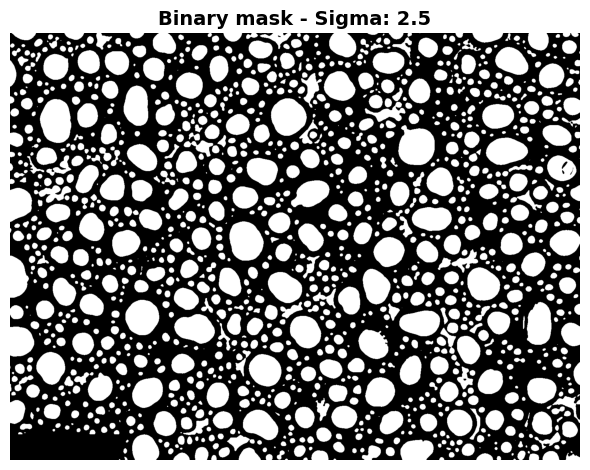

In [64]:
# 1. Caricamento immagine di microscopia
image_path = Path("/Users/lucaasinari/Desktop/Tesi ESPCI/esperimenti/data/immagini_micro/2026_10_19_ATP_PLL_250mM_correctedPLL.ses/0008.tif")
image = io.imread(image_path)
image_gray = rgb2gray(image) if image.ndim == 3 else image.astype(float) / 255.0

# 2. Equalizzazione adattiva (CLAHE) e pre-processing
image_enhanced = exposure.equalize_adapthist(image_gray, clip_limit=0.03)
image_inverted = 1.0 - image_enhanced

# Applichiamo un leggero blur Gaussiano
sigma = 2.5
image_blurred = gaussian(image_inverted, sigma)

# 3. Segmentazione: Algoritmo di Otsu
thresh = threshold_otsu(image_blurred)
binary_image = image_blurred > thresh

# Rimozione manuale della barra di scala
binary_image[1128:, :306] = False


# 4. Etichettatura e Calcolo delle Proprietà dei Blob (Regionprops)
label_img = label(binary_image)
regions = regionprops(label_img)

blobs = []
for props in regions:
    y0, x0 = props.centroid
    r = np.sqrt(props.area / np.pi)
    blobs.append((y0, x0, r))

blobs = np.array(blobs) if len(blobs) > 0 else np.empty((0, 3))

print(f"Totale coacervati rilevati: {len(blobs)}")

# 5. Visualizzazione in 3 finestre separate

# --- Figura 1: Immagine Originale ---
plt.figure(figsize=(6, 6), dpi=100)
plt.imshow(image_gray, cmap="gray")
plt.title("Microscopy BF image", fontsize=14, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "microscopy_aoriginal.png", dpi=300)
plt.show()

# --- Figura 2: Cerchi rilevati sovrapposti all'immagine ---
plt.figure(figsize=(6, 6), dpi=100)
plt.imshow(image_gray, cmap="gray")
for y, x, r in blobs:
    c = plt.Circle((x, y), r, color="lime", linewidth=1.2, fill=False)
    plt.gca().add_patch(c)
plt.title(f"Blob detection ({len(blobs)} coacervates)", fontsize=14, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "microscopy_blobs_detection.png", dpi=300)
plt.show()

# --- Figura 3: Maschera Binaria ---
plt.figure(figsize=(6, 6), dpi=100)
plt.imshow(binary_image, cmap="gray")
plt.title(f"Binary mask - Sigma: {sigma}", fontsize=14, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "microscopy_binary_mask.png", dpi=300)
plt.show()

In [65]:
H, L = image_gray.shape
img_area_um2 = H * L * (pixel_size_um ** 2)
tot_volume_um3=img_area_um2 * 400 #capillary heigh is 400um

radii_um = blobs[:, 2] * pixel_size_um
coac_volumes_um3 =  (4 / 3) * np.pi * (radii_um ** 3) #moltiplico per 0.5 perchè emisfere
tot_coac_volume_um3 = np.sum(coac_volumes_um3)
volume_fraction_coac=tot_coac_volume_um3/tot_volume_um3
print(f"Coacervate volume fraction: {volume_fraction_coac:.3f}")

CC_concentration_250 = ((10-SN_concentration[5])/(volume_fraction_coac))+SN_concentration[5] #mM
print(f"Coacervate Concentration: {CC_concentration_250:.3f}")

if CC_concentration_250 < 0:
    print("\n⚠️ WARNING: Coacervate Concentration value is negative!")

Coacervate volume fraction: 0.008
Coacervate Concentration: 1020.665


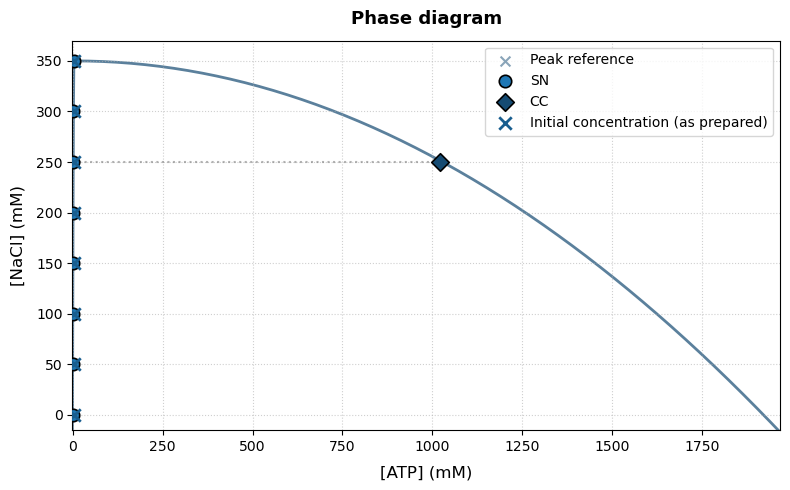

In [78]:
extinction_factor = 15.4 #mM^{-1} cm^{-1}
concentration = np.array(ABSORBANCE) / extinction_factor
SALT = np.array(SALT)

mask_sub = SALT <= critical_point
mask_sup = SALT > critical_point

# --- 1. DEFINIZIONE MANUALE DELLA CURVA A CAMPANA (BINODALE) ---
# Inserisci qui i parametri della tua curva asimmetrica:

# Punto in cui la curva tocca l'asse a sinistra
x_left = -1.0     
y_left = -15.0    

# Punto di picco massimo della curva
x_peak = concentration[mask_sub][-1] + 1 
y_peak = critical_point

# Punto in cui la curva tocca l'asse a destra
x_right = CC_concentration_250 + 942   
y_right = -15.0   

# --- Costruzione matematica della curva (due mezze parabole unite al picco) ---
# Ramo sinistro (da x_left a x_peak)
x_curve_left = np.linspace(x_left, x_peak, 100)
a_left = (y_left - y_peak) / (x_left - x_peak)**2
y_curve_left = a_left * (x_curve_left - x_peak)**2 + y_peak

# Ramo destro (da x_peak a x_right)
x_curve_right = np.linspace(x_peak, x_right, 100)
a_right = (y_right - y_peak) / (x_right - x_peak)**2
y_curve_right = a_right * (x_curve_right - x_peak)**2 + y_peak

# Unione dei due rami (ignoriamo il primo punto del ramo destro per non duplicare il picco)
x_curve = np.concatenate((x_curve_left, x_curve_right[1:]))
y_curve = np.concatenate((y_curve_left, y_curve_right[1:]))

####################

plt.figure(figsize=(8, 5), dpi=100)

# Disegna la curva manuale asimmetrica
plt.plot(x_curve, y_curve, color="#154b73", linestyle="-", linewidth=2, zorder=1, alpha=0.7)#, label="Binodal curve (Manual)")

# (Opzionale) Disegna un marcatore leggero sul picco per aiutarti visivamente a regolarlo
plt.scatter(x_peak, y_peak, color="#154b73", marker="x", s=50, alpha=0.5, zorder=2, label="Peak reference")

# Scatter plot: Punti del surnatante (SN) - opachi se <= critical_point, trasparenti se > critical_point
plt.scatter(concentration[mask_sub], SALT[mask_sub], color="#1f77b4", s=80, edgecolors="black", linewidth=1.2, zorder=3, label="SN")
#if np.any(mask_sup):
#    plt.scatter(concentration[mask_sup], SALT[mask_sup], color="#1f77b4", s=80, edgecolors="black", linewidth=1.2, alpha=0.3, zorder=3)

# --- NUOVO PUNTO COACERVATO ---
# Assicurati di aver definito la variabile CC_concentration_250 altrove nel codice
plt.scatter(CC_concentration_250, 250, color="#154b73", marker="D", s=80, edgecolors="black", linewidth=1.2, zorder=4, label="CC")

# Punti a x = 10 allineati in orizzontale (stesso valore di SALT)
x_ref = np.full_like(SALT, 2.5)
plt.scatter(x_ref[mask_sub], SALT[mask_sub], marker="x", color="#195e8f", s=80, linewidth=2.0, zorder=3, label="Initial concentration (as prepared)")

# Tie-lines (Linee orizzontali di collegamento): SOLO per punti <= critical_point
for c, s in zip(concentration[mask_sub], SALT[mask_sub]):
    plt.plot([c, 10], [s, s], linestyle=":", color="gray", alpha=0.6, zorder=2)

# Tie-line per il nuovo punto a 250 mM (se <= critical_point)
if 250 <= critical_point:
    plt.plot([CC_concentration_250, 10], [250, 250], linestyle=":", color="gray", alpha=0.6, zorder=2)

# Retta verticale ATP 10mM misurato
#if "ATP_ABSORBANCE" in globals() and not np.isnan(ATP_ABSORBANCE):
#    atp_10mM_conc = ATP_ABSORBANCE / extinction_factor
#    plt.axvline(x=atp_10mM_conc, color="red", linestyle="--", linewidth=1.5, alpha=0.8, zorder=2, label=f"ATP 10mM ({atp_10mM_conc:.2f} mM)")

# Dettagli del grafico
plt.xlabel("[ATP] (mM)", fontsize=12, labelpad=8)
plt.ylabel("[NaCl] (mM)", fontsize=12, labelpad=8)
plt.title("Phase diagram", fontsize=13, fontweight="bold", pad=12)
plt.grid(True, linestyle=":", alpha=0.6, zorder=0)
plt.legend(frameon=True)

# Impostazione limiti assi (si adattano automaticamente ai punti scelti)
plt.xlim(-1, x_right + 5)
plt.ylim(-15, y_peak + 20)
#plt.xscale("log")
plt.tight_layout()

# Salvataggio grafico
plt.savefig(OUTPUT_DIR / "phase_diagram_complete.png", dpi=300)
plt.show()

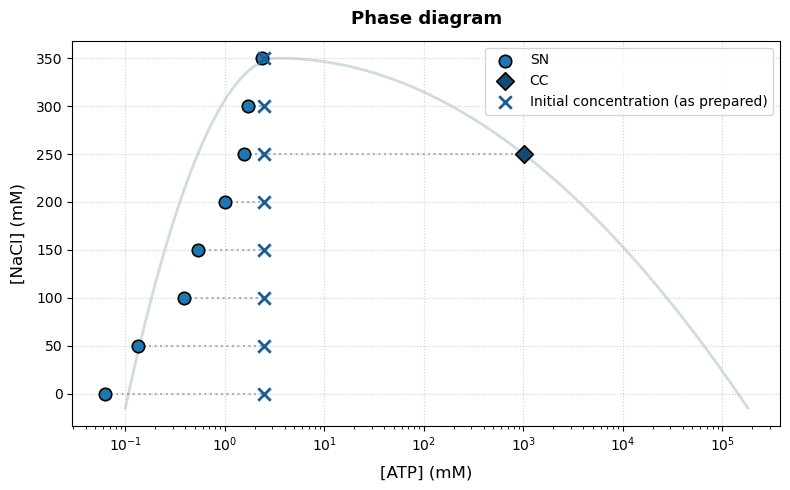

In [85]:
# --- 1. DEFINIZIONE MANUALE DELLA CURVA A CAMPANA (BINODALE IN LOG-SPACE) ---
# I punti x devono essere strettamente > 0 per la scala logaritmica
x_left = 0.1     # Sostituito -1.0 con un numero positivo (es. 0.1 o 0.01)
y_left = -15.0    

# Punto di picco massimo della curva
x_peak = concentration[mask_sub][-1] + 1 
y_peak = critical_point

# Punto in cui la curva tocca l'asse a destra
x_right = CC_concentration_250 + 180000   
y_right = -15.0   

# Passaggio al logaritmo per calcolare la parabola nello spazio visivo corretto
log_x_left = np.log10(x_left)
log_x_peak = np.log10(x_peak)
log_x_right = np.log10(x_right)

# Ramo sinistro (costruito nello spazio logaritmico)
log_x_curve_left = np.linspace(log_x_left, log_x_peak, 100)
a_left = (y_left - y_peak) / (log_x_left - log_x_peak)**2
y_curve_left = a_left * (log_x_curve_left - log_x_peak)**2 + y_peak
x_curve_left = 10**log_x_curve_left # Riconversione in lineare per il plot

# Ramo destro (costruito nello spazio logaritmico)
log_x_curve_right = np.linspace(log_x_peak, log_x_right, 100)
a_right = (y_right - y_peak) / (log_x_right - log_x_peak)**2
y_curve_right = a_right * (log_x_curve_right - log_x_peak)**2 + y_peak
x_curve_right = 10**log_x_curve_right # Riconversione in lineare per il plot

# Unione dei due rami (ignoriamo il primo punto del ramo destro per non duplicare il picco)
x_curve = np.concatenate((x_curve_left, x_curve_right[1:]))
y_curve = np.concatenate((y_curve_left, y_curve_right[1:]))

plt.figure(figsize=(8, 5), dpi=100)

# Disegna la curva manuale asimmetrica
plt.plot(x_curve, y_curve, color="#154b73", linestyle="-", linewidth=2, zorder=1, alpha=0.2)#, label="Binodal curve (Manual)")

# (Opzionale) Disegna un marcatore leggero sul picco per aiutarti visivamente a regolarlo
#plt.scatter(x_peak, y_peak, color="#154b73", marker="x", s=50, alpha=0.5, zorder=2, label="Peak reference")

# Scatter plot: Punti del surnatante (SN) - opachi se <= critical_point, trasparenti se > critical_point
plt.scatter(concentration[mask_sub], SALT[mask_sub], color="#1f77b4", s=80, edgecolors="black", linewidth=1.2, zorder=3, label="SN")
#if np.any(mask_sup):
#    plt.scatter(concentration[mask_sup], SALT[mask_sup], color="#1f77b4", s=80, edgecolors="black", linewidth=1.2, alpha=0.3, zorder=3)

# --- NUOVO PUNTO COACERVATO ---
# Assicurati di aver definito la variabile CC_concentration_250 altrove nel codice
plt.scatter(CC_concentration_250, 250, color="#154b73", marker="D", s=80, edgecolors="black", linewidth=1.2, zorder=4, label="CC")

# Punti a x = 10 allineati in orizzontale (stesso valore di SALT)
x_ref = np.full_like(SALT, 2.5)
plt.scatter(x_ref[mask_sub], SALT[mask_sub], marker="x", color="#195e8f", s=80, linewidth=2.0, zorder=3, label="Initial concentration (as prepared)")

# Tie-lines (Linee orizzontali di collegamento): SOLO per punti <= critical_point
for c, s in zip(concentration[mask_sub], SALT[mask_sub]):
    plt.plot([c, 2.5], [s, s], linestyle=":", color="gray", alpha=0.6, zorder=2)

# Tie-line per il nuovo punto a 250 mM (se <= critical_point)
if 250 <= critical_point:
    plt.plot([CC_concentration_250, 2.5], [250, 250], linestyle=":", color="gray", alpha=0.6, zorder=2)

# Retta verticale ATP 10mM misurato
#if "ATP_ABSORBANCE" in globals() and not np.isnan(ATP_ABSORBANCE):
#    atp_10mM_conc = ATP_ABSORBANCE / extinction_factor
#    plt.axvline(x=atp_10mM_conc, color="red", linestyle="--", linewidth=1.5, alpha=0.8, zorder=2, label=f"ATP 10mM ({atp_10mM_conc:.2f} mM)")

# Dettagli del grafico
plt.xlabel("[ATP] (mM)", fontsize=12, labelpad=8)
plt.ylabel("[NaCl] (mM)", fontsize=12, labelpad=8)
plt.title("Phase diagram", fontsize=13, fontweight="bold", pad=12)
plt.grid(True, linestyle=":", alpha=0.6, zorder=0)
plt.legend(frameon=True)

# Impostazione limiti assi (si adattano automaticamente ai punti scelti)
#plt.xlim(-1, x_right + 5)
#plt.ylim(-15, y_peak + 20)
plt.xscale("log")
plt.tight_layout()

# Salvataggio grafico
plt.savefig(OUTPUT_DIR / "phase_diagram_complete_log.png", dpi=300)